# Chapter 21: The singular value decomposition and PCA

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-4/21-svd-pca.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/21-svd-pca.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

## In code

`np.linalg.svd` returns $\mathbf{U}$, the singular values as a list, and $\mathbf{V}^{\mathsf{T}}$ (not $\mathbf{V}$). MATLAB's `svd` returns $\mathbf{U}$, $\mathbf{\Sigma}$ and $\mathbf{V}$. With `full_matrices=False`, or `'econ'` in MATLAB, a tall matrix gets only the columns of $\mathbf{U}$ that matter, which saves a lot of memory for data sets.

In [1]:
import numpy as np

A = np.array([[3, 0], [4, 5]])
U, s, Vt = np.linalg.svd(A)
print(s)                                   # 3*sqrt(5) and sqrt(5)
print(U)
print(Vt)                                  # rows are v1 and v2 (signs may differ)

# PCA of Example 3
X = np.array([[1, 2], [2, 3], [3, 5], [4, 4], [5, 6]])
Xc = X - X.mean(axis=0)                    # centre each column
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
print(Vt[0])                               # first principal component
print(s**2 / np.sum(s**2))                 # fraction of variance explained

[6.70820393 2.23606798]
[[-0.31622777 -0.9486833 ]
 [-0.9486833   0.31622777]]
[[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]
[0.70710678 0.70710678]
[0.95 0.05]


[Figure 21.2](https://trgoodale.github.io/matrix-book/part-4/21-svd-pca.html#fig-svd-compress) compresses a $120 \times 120$ picture, made of simple shapes, by keeping $k$ terms of its SVD.

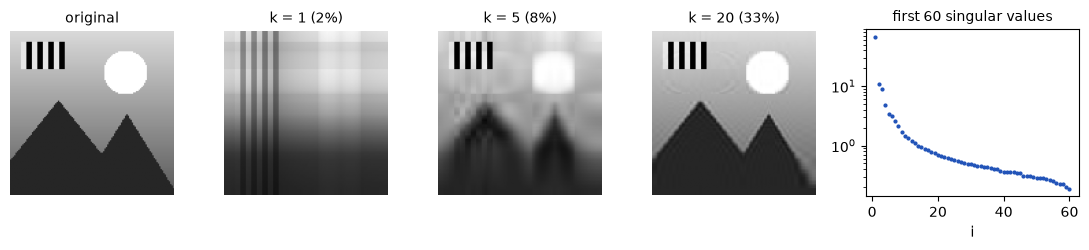

In [2]:
import matplotlib.pyplot as plt

n = 120
y, x = np.mgrid[0:n, 0:n]
img = 0.85 - 0.5 * y / n                                   # sky, darker lower down
img[(x - 84)**2 + (y - 30)**2 < 16**2] = 1.0               # sun
ridge = np.minimum(np.abs(x - 35) * 1.25 + 50, np.abs(x - 85) * 1.6 + 60)
img[y > ridge] = 0.15                                      # mountains
img[8:28, 8:40] = np.where((x[8:28, 8:40] // 4) % 2, 0.0, 0.9)   # stripes

U, s, Vt = np.linalg.svd(img)
fig, axes = plt.subplots(1, 5, figsize=(11, 2.6), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.3]})
for ax, k in zip(axes[:4], [None, 1, 5, 20]):
    approx = img if k is None else (U[:, :k] * s[:k]) @ Vt[:k]
    ax.imshow(np.clip(approx, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title("original" if k is None else f"k = {k} ({100 * k * (2 * n + 1) / n**2:.0f}%)", fontsize=10)
    ax.axis("off")
axes[4].semilogy(np.arange(1, 61), s[:60], ".", ms=4, color="#2153b8")
axes[4].set_title("first 60 singular values", fontsize=10)
axes[4].set_xlabel("i")
plt.tight_layout()
plt.show()

## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-4/21-svd-pca.html#sec-svd-pca-exercises). Worked solutions are in the notebook `solutions-part-4.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-4.html#sec-solutions-svd-pca).

### Exercise 7

Generate data for 200 people with two closely related measurements, for example with `rng = np.random.default_rng(1)`, `h = rng.normal(170, 10, 200)` (heights in cm) and `s = h + rng.normal(0, 4, 200)` (arm spans in cm). Find the principal components and the fraction of the variance explained by each, and interpret the first component.

In [3]:
# Your code here